# code_105 · Initialization, saturation and propagation through depth

**Book:** section 21.3. A self-contained neural-training laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_21_GUIDE.md), [run evidence](../CHAPTER_21_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_105).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2205;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2205


<a id="propagation"></a>
 ## Hold the computation fixed before comparing initializers
 Propagate 128 fixed normal input records through twelve width-32 hidden layers. Six declared conditions vary activation and initialization: large sigmoid weights, tiny ReLU weights, large ReLU weights, fan-in Kaiming ReLU, negative-bias dead ReLU, and gain-adjusted Xavier tanh. Three seeds repeat each condition; no training or target-based initializer selection occurs. The diagnostic loss is the mean square of the final hidden output. Activation spread, inactive/saturated fractions and per-layer weight-gradient RMS have explicit definitions. A variance prescription is not an exact finite-network guarantee.


activation_SD  gradient_RMS  \
condition     depth                                
ReLU Kaiming  1       8.078354e-01  8.796630e-03   
              12      4.585795e-01  2.010640e-02   
ReLU dead     1       0.000000e+00  0.000000e+00   
              12      0.000000e+00  0.000000e+00   
ReLU large    1       6.462683e+00  5.192614e+18   
              12      3.151335e+10  1.186872e+19   
ReLU tiny     1       3.231341e-03  6.190078e-58   
              12      7.693688e-30  1.414862e-57   
Sigmoid large 1       4.618711e-01  3.684679e-04   
              12      4.474429e-01  1.759951e-03   
Tanh Xavier   1       7.491979e-01  3.495557e-03   
              12      6.484521e-01  3.650845e-03   

                     inactive_or_saturated_fraction  
condition     depth                                  
ReLU Kaiming  1                            0.496501  
              12                           0.472982  
ReLU dead     1                            1.000000  
              12                           1.000000  
ReLU large    1                            0.496501  
              12                           0.472982  
ReLU tiny     1                            0.496501  
              12                           0.472982  
Sigmoid large 1                            0.667318  
              12                           0.533285  
Tanh Xavier   1                            0.100423  
              12                           0.015381

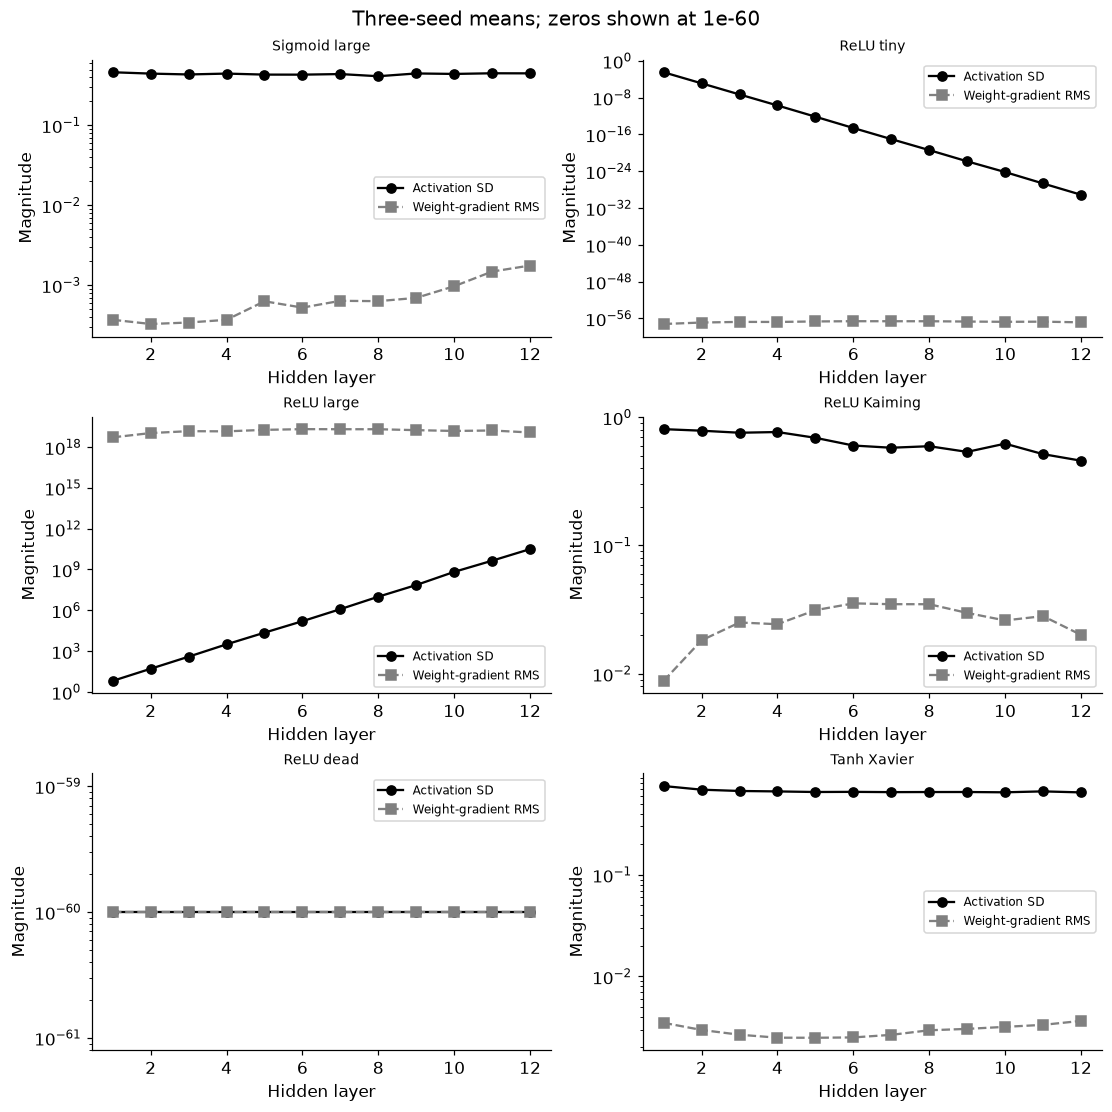

In [2]:
x=torch.tensor(rng.normal(size=(128,32)))
configurations=[('Sigmoid large','sigmoid','large'),('ReLU tiny','relu','tiny'),('ReLU large','relu','large'),('ReLU Kaiming','relu','kaiming'),('ReLU dead','relu','dead'),('Tanh Xavier','tanh','xavier')]
observations=[]
for name,activation,initialization in configurations:
    for replicate in range(3):
        torch.manual_seed(SEED+replicate);layers=[];values=[];h=x
        for depth in range(12):
            layer=nn.Linear(32,32);nn.init.zeros_(layer.bias)
            if initialization=='kaiming':nn.init.kaiming_normal_(layer.weight,mode='fan_in',nonlinearity='relu')
            elif initialization=='xavier':nn.init.xavier_normal_(layer.weight,gain=nn.init.calculate_gain('tanh'))
            else:nn.init.normal_(layer.weight,std={'large':2.,'tiny':.001,'dead':.01}[initialization])
            if initialization=='dead':nn.init.constant_(layer.bias,-5.)
            z=layer(h);h={'relu':torch.relu,'tanh':torch.tanh,'sigmoid':torch.sigmoid}[activation](z);layers.append(layer);values.append(h)
        loss=torch.mean(h*h);loss.backward();assert torch.isfinite(loss)
        for depth,(layer,value) in enumerate(zip(layers,values),1):
            detached=value.detach();fraction=float((detached==0).double().mean()) if activation=='relu' else float(((detached<.01)|(detached>.99)).double().mean()) if activation=='sigmoid' else float((detached.abs()>.99).double().mean())
            gradient=float(torch.sqrt(torch.mean(layer.weight.grad**2)));assert np.isfinite(gradient)
            observations.append({'condition':name,'replicate':replicate,'depth':depth,'activation_SD':float(detached.std(correction=0)),'gradient_RMS':gradient,'inactive_or_saturated_fraction':fraction,'final_loss':float(loss.detach())})
frame=pd.DataFrame(observations);profiles=[]
for (name,depth),part in frame.groupby(['condition','depth'],sort=True):profiles.append({'condition':name,'depth':int(depth),'mean_activation_SD':float(part.activation_SD.mean()),'mean_gradient_RMS':float(part.gradient_RMS.mean()),'mean_inactive_or_saturated_fraction':float(part.inactive_or_saturated_fraction.mean())})
dead=frame[frame.condition=='ReLU dead'];assert np.all(dead.gradient_RMS==0) and np.all(dead.inactive_or_saturated_fraction==1)
RESULTS.update(profiles=profiles,individual_profiles=observations,depth=12,width=32,replicates=3,loss_contract='mean square of final hidden activations')
display(frame[frame.depth.isin([1,12])].groupby(['condition','depth'])[['activation_SD','gradient_RMS','inactive_or_saturated_fraction']].mean())
fig,axes=plt.subplots(3,2,figsize=(10,10))
for ax,(name,activation,initialization) in zip(axes.flat,configurations):
    part=[r for r in profiles if r['condition']==name];depths=[r['depth'] for r in part]
    ax.semilogy(depths,[max(r['mean_activation_SD'],1e-60) for r in part],'o-',color='black',label='Activation SD')
    ax.semilogy(depths,[max(r['mean_gradient_RMS'],1e-60) for r in part],'s--',color='.5',label='Weight-gradient RMS');ax.set(title=name,xlabel='Hidden layer',ylabel='Magnitude');ax.legend(fontsize=8)
fig.suptitle('Three-seed means; zeros shown at 1e-60');plt.show()


<a id="diagnostic-limits"></a>
 ## Diagnose the obstruction before changing the model
 Saturation here means sigmoid output outside [0.01,0.99] or absolute tanh output above 0.99; a ReLU inactive fraction counts exact zero outputs. These are descriptive thresholds, not universal failure certificates. The dead condition deliberately uses bias -5 and small weights, giving zero activation and parameter gradients. Extremely small or large scales obstruct useful propagation under this particular depth and loss. Means over three seeds are descriptive; they do not establish a population interval, convergence or predictive superiority of one activation family.


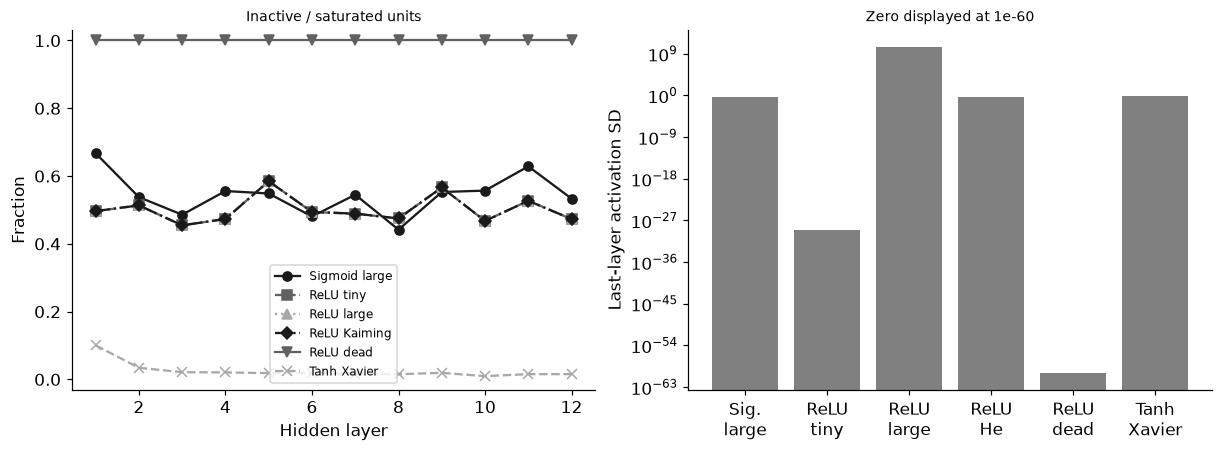

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for index,(name,activation,initialization) in enumerate(configurations):
    part=[r for r in profiles if r['condition']==name];axes[0].plot([r['depth'] for r in part],[r['mean_inactive_or_saturated_fraction'] for r in part],linestyle=['-','--',':','-.','-','--'][index],marker=['o','s','^','D','v','x'][index],color=str(.1+.28*(index%3)),label=name)
axes[0].set(xlabel='Hidden layer',ylabel='Fraction',ylim=(-.03,1.03),title='Inactive / saturated units');axes[0].legend(fontsize=8)
names=[row[0] for row in configurations];last=[next(r for r in profiles if r['condition']==name and r['depth']==12) for name in names]
axes[1].bar(range(6),[max(r['mean_activation_SD'],1e-60) for r in last],color='.5');axes[1].set(yscale='log',xticks=range(6),xticklabels=['Sig.\nlarge','ReLU\ntiny','ReLU\nlarge','ReLU\nHe','ReLU\ndead','Tanh\nXavier'],ylabel='Last-layer activation SD',title='Zero displayed at 1e-60');plt.show()
assert len(profiles)==72 and len(observations)==216


In [4]:
summary={'example_id':'code_105','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['activation and gradient propagation', 'Xavier and Kaiming controls', 'dead ReLU units', 'finite-depth initialization diagnostics'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["activation and gradient propagation", "Xavier and Kaiming controls", "dead ReLU units", "finite-depth initialization diagnostics"], "elapsed_seconds": 1.249, "example_id": "code_105", "hardware": "Darwin arm64 CPU", "results": {"depth": 12, "individual_profiles": [{"activation_SD": 0.4618794521469733, "condition": "Sigmoid large", "depth": 1, "final_loss": 0.49845214845568264, "gradient_RMS": 0.00037185087933768227, "inactive_or_saturated_fraction": 0.67138671875, "replicate": 0}, {"activation_SD": 0.4504633552389273, "condition": "Sigmoid large", "depth": 2, "final_loss": 0.49845214845568264, "gradient_RMS": 0.0002913516341710464, "inactive_or_saturated_fraction": 0.579345703125, "replicate": 0}, {"activation_SD": 0.43290734210712095, "condition": "Sigmoid large", "depth": 3, "final_loss": 0.49845214845568264, "gradient_RMS": 0.00037424665048754307, "inactive_or_saturated_fraction": 0.4951171875, "replicate": 0}, {"activation_SD": 0.4